# Wine Quality Prediction — Data Analysis & Model Training

**Student:** Binay Chaudhary (25123792)
**Dataset:** `WineQT.csv` — 1,143 wine samples, 13 columns (11 physicochemical features, `quality` target, `Id` identifier)

This notebook covers dataset loading, exploratory data analysis, preprocessing, training and
evaluation of three classification models (Logistic Regression, Random Forest, Gradient Boosting),
and serialization of the selected model for use by the Django web application.

In [1]:
import json
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize

sns.set_style("whitegrid")
%matplotlib inline

RANDOM_STATE = 42
DATA_PATH = Path("../data/WineQT.csv")
MODEL_DIR = Path("../model")
MODEL_DIR.mkdir(exist_ok=True)

## 1. Load the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


### 1.1 Data quality checks

Check for missing values and duplicate rows before proceeding to modelling.

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal duplicate rows:", df.duplicated().sum())

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Total duplicate rows: 0


### 1.2 Feature / target split

The 11 physicochemical measurements are the predictive features. `quality` is the target
variable. `Id` is a row identifier and is excluded from modelling.

In [5]:
FEATURE_COLUMNS = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide",
    "density", "pH", "sulphates", "alcohol",
]
TARGET_COLUMN = "quality"

X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].copy()
print("Features:", X.shape, " Target:", y.shape)

Features: (1143, 11)  Target: (1143,)


## 2. Exploratory Data Analysis

In [6]:
quality_counts = y.value_counts().sort_index()
quality_pct = (quality_counts / len(y) * 100).round(2)
pd.DataFrame({"count": quality_counts, "percentage": quality_pct})

,count,percentage
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40


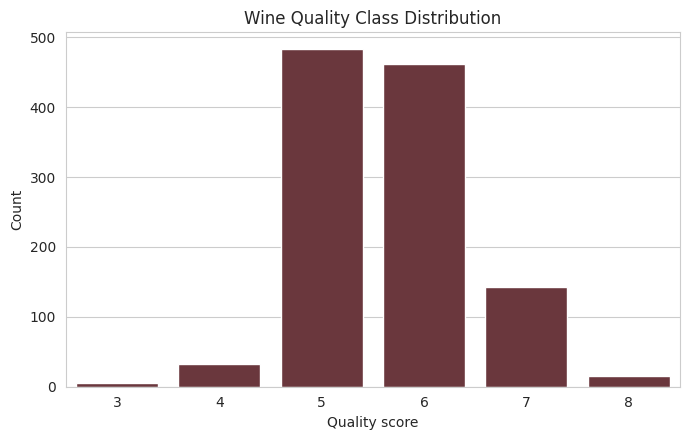

In [7]:
plt.figure(figsize=(7, 4.5))
sns.countplot(x=y, order=sorted(y.unique()), color="#722F37")
plt.title("Wine Quality Class Distribution")
plt.xlabel("Quality score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

The class distribution is imbalanced: quality scores 5 and 6 make up the majority of samples, while scores 3 and 8 are rare. This motivates the use of **macro-averaged** evaluation metrics, which weight every class equally regardless of its frequency.

In [8]:
X.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
fixed acidity,8.311,1.748,4.600,15.900
volatile acidity,0.531,0.180,0.120,1.580
citric acid,0.268,0.197,0.000,1.000
residual sugar,2.532,1.356,0.900,15.500
chlorides,0.087,0.047,0.012,0.611
free sulfur dioxide,15.615,10.250,1.000,68.000
total sulfur dioxide,45.915,32.782,6.000,289.000
density,0.997,0.002,0.990,1.004
pH,3.311,0.157,2.740,4.010
sulphates,0.658,0.170,0.330,2.000


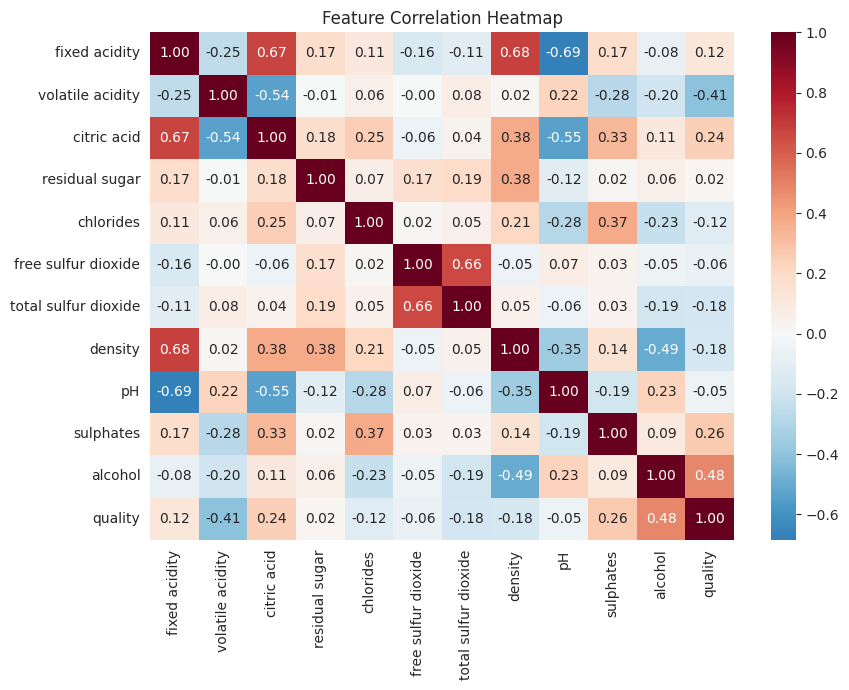

In [9]:
plt.figure(figsize=(9, 7))
corr = df[FEATURE_COLUMNS + [TARGET_COLUMN]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 3. Preprocessing

A stratified 80/20 train-test split preserves the class proportions of the imbalanced target across both sets. Logistic Regression uses standardised features; the tree-based models (Random Forest, Gradient Boosting) do not require scaling.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

classes = sorted(y.unique())
print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 914  Test size: 229


## 4. Model Training & Evaluation

Three classifiers are trained and compared using accuracy, macro precision, macro recall, macro F1-score and macro (one-vs-rest) ROC-AUC.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

results = {}
fitted = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)

    y_test_bin = label_binarize(y_test, classes=model.classes_)
    try:
        auc = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")
    except ValueError:
        auc = float("nan")

    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "macro_roc_auc": auc,
    }
    fitted[name] = model

results_df = pd.DataFrame(results).T.round(3)
results_df

,accuracy,macro_precision,macro_recall,macro_f1,macro_roc_auc
Logistic Regression,0.624,0.286,0.287,0.285,0.810
Random Forest,0.712,0.359,0.343,0.345,0.834
Gradient Boosting,0.659,0.322,0.321,0.321,0.766


### 4.1 Confusion matrices

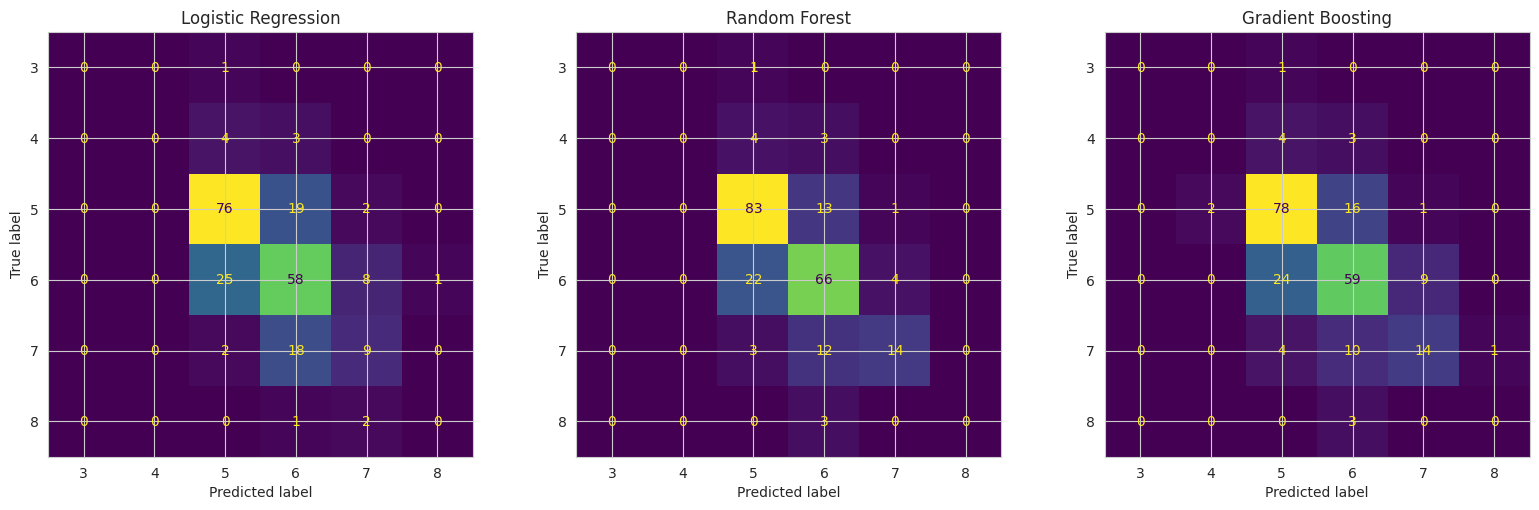

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, model) in zip(axes, fitted.items()):
    X_eval = X_test_scaled if name == "Logistic Regression" else X_test
    ConfusionMatrixDisplay.from_estimator(model, X_eval, y_test, labels=classes, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 5. Model Selection

The model with the highest macro F1-score is selected for deployment in the Django application, since macro F1 balances precision and recall across all quality classes, including the rare ones.

In [13]:
best_name = results_df["macro_f1"].astype(float).idxmax()
best_model = fitted[best_name]
print("Selected model:", best_name)
results_df

Selected model: Random Forest


,accuracy,macro_precision,macro_recall,macro_f1,macro_roc_auc
Logistic Regression,0.624,0.286,0.287,0.285,0.810
Random Forest,0.712,0.359,0.343,0.345,0.834
Gradient Boosting,0.659,0.322,0.321,0.321,0.766


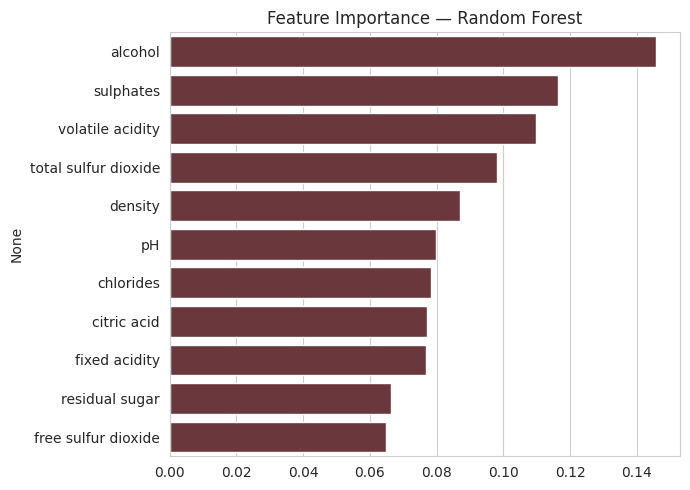

In [14]:
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=FEATURE_COLUMNS).sort_values(ascending=False)
    plt.figure(figsize=(7, 5))
    sns.barplot(x=importances.values, y=importances.index, color="#722F37")
    plt.title(f"Feature Importance — {best_name}")
    plt.tight_layout()
    plt.show()
    importances

## 6. Persist Model Artifacts

The selected classifier, the fitted scaler and the feature order are saved so the Django application (`predictor/ml_model.py`) can load them at server start-up and run inference on user-submitted measurements.

In [15]:
with open(MODEL_DIR / "wine_quality_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open(MODEL_DIR / "scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

metadata = {
    "model_name": best_name,
    "uses_scaler": best_name == "Logistic Regression",
    "feature_order": FEATURE_COLUMNS,
    "classes": [int(c) for c in classes],
    "metrics": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in results.items()},
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}
with open(MODEL_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", MODEL_DIR / "wine_quality_model.pkl")
print("Saved:", MODEL_DIR / "scaler.pkl")
print("Saved:", MODEL_DIR / "model_metadata.json")

Saved: ../model/wine_quality_model.pkl
Saved: ../model/scaler.pkl
Saved: ../model/model_metadata.json


## 7. Conclusion

All three models were evaluated on a common stratified 80/20 test split (random state 42). The selected model above is serialized and loaded by the Django backend to serve predictions from the wine-quality web form. Macro-averaged metrics remain considerably lower than raw accuracy, reflecting the difficulty of predicting the under-represented quality classes (3 and 8).